# Review Opinion Miner: Data Foundation + Q1 Sentiment Baseline
**DS311 Data Mining · Fall 2026 · P05** · Notebook `B1_data_foundation_and_sentiment_baseline.ipynb`
**Author:** Ali Murad (Mining lead) · builds on Awais Khan's Week 7 notebook (Data lead)

**What this notebook does**

| Part | Pipeline stage (course guide) | What is new compared with the earlier notebook |
|---|---|---|
| 1 | Acquire and integrate | Full All_Beauty data (701K reviews), not the first 1,000 rows; reviews **joined with product metadata** (brand, price); data dictionary |
| 2 | Data-quality report | Missing values, duplicates, empty text, **outliers**, and a decision table with a reason for each choice |
| 3 | Deliberate sampling | Random 150K sample with a fixed seed, **checked against the full data**, saved for the whole team |
| 4 | Explore | EDA on the full cleaned data: ratings, time trends, brands, length, distinctive words |
| 5 | Hypothesis tests | Three tests with effect sizes |
| 6 | Leakage check (for Q3) | Shows that older reviews collect more helpful votes |
| 7 | Q1 first model | TF-IDF + Naive Bayes / Logistic Regression sentiment classifier, 5-fold CV, against a majority baseline |
| 8 | Evaluate and interpret | Confusion matrix, error analysis, the words the model relies on, a "paste a review" demo |

Runs top-to-bottom on free Colab (CPU). **Runtime → Run all.** It takes about 15–20 minutes, most of it the download and the cross-validation.

## 0. Setup

In [1]:
import gzip, json, os, re, time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42                      # one seed for every random step (reproducibility)
np.random.seed(SEED)

DATA_DIR = "data"              # downloaded raw files
OUT_DIR = "outputs"            # results, sample, model
FIG_DIR = "figures"            # charts for the report
for d in (DATA_DIR, OUT_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# Colour convention: sentiment is a polarity -> red = negative, grey = neutral, blue = positive
SENT_ORDER = ["negative", "neutral", "positive"]
SENT_COLORS = {"negative": "#d64545", "neutral": "#8a8a8a", "positive": "#2a78d6"}
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


## 1. Acquire and integrate
Source: **Amazon Reviews 2023**, McAuley Lab, UCSD (Hou et al., 2024), category **All_Beauty**. There are two tables:
- **reviews**: one row per review (rating, text, time, helpful votes, verified flag)
- **meta**: one row per product (title, brand/`store`, price)

They are joined on `parent_asin`. The files download straight from the official site, so nothing large is stored in GitHub.

In [2]:
CATEGORY = "All_Beauty"
BASE = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw"
FILES = {
    "reviews": (f"{BASE}/review_categories/{CATEGORY}.jsonl.gz", f"{DATA_DIR}/{CATEGORY}.jsonl.gz"),
    "meta":    (f"{BASE}/meta_categories/meta_{CATEGORY}.jsonl.gz", f"{DATA_DIR}/meta_{CATEGORY}.jsonl.gz"),
}
MIRROR = "https://datarepo.eng.ucsd.edu/mcauley_group/data/amazon_2023/raw"   # backup link listed on Hugging Face
for name, (url, path) in FILES.items():
    if not os.path.exists(path):
        print(f"Downloading {name} ...")
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as e:
            print(f"  main link failed ({e}); trying the UCSD mirror")
            urllib.request.urlretrieve(url.replace(BASE, MIRROR), path)
    print(f"{name:8s} {os.path.getsize(path)/1e6:6.1f} MB  {path}")

reviews    94.4 MB  data/All_Beauty.jsonl.gz
meta       39.9 MB  data/meta_All_Beauty.jsonl.gz


In [3]:
def read_jsonl(path, cols):
    # Stream a .jsonl.gz file line by line and keep only the columns we need (saves RAM on Colab).
    rows = []
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            row = {c: r.get(c) for c in cols}
            if "images" in cols:                      # keep only how many images were attached
                row["images"] = len(r.get("images") or [])
            rows.append(row)
    return pd.DataFrame(rows)

review_cols = ["rating", "title", "text", "images", "asin", "parent_asin",
               "user_id", "timestamp", "helpful_vote", "verified_purchase"]
meta_cols = ["parent_asin", "title", "store", "price", "average_rating", "rating_number"]

t0 = time.time()
reviews = read_jsonl(FILES["reviews"][1], review_cols)
meta = read_jsonl(FILES["meta"][1], meta_cols)
print(f"reviews: {reviews.shape} | meta: {meta.shape} | loaded in {time.time()-t0:.0f}s")

reviews: (701528, 10) | meta: (112590, 6) | loaded in 23s


In [4]:
# Join: every review gets its product's title, brand and price (left join keeps all reviews)
meta = meta.rename(columns={"title": "product_title", "store": "brand"})
meta = meta.drop_duplicates("parent_asin")
df_raw = reviews.merge(meta, on="parent_asin", how="left", validate="many_to_one")

match_rate = df_raw["product_title"].notna().mean()
del reviews                                   # free RAM: df_raw now holds everything
print("Joined shape:", df_raw.shape)
print(f"Reviews matched to a product record: {match_rate:.1%}")
df_raw.head(3)

Joined shape: (701528, 15)
Reviews matched to a product record: 100.0%


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,product_title,brand,price,average_rating,rating_number
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,0,B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True,Herbivore - Natural Sea Mist Texturizing Salt ...,HERBIVORE,NaN,4.3,384
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",0,B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True,All Natural Vegan Dry Shampoo Powder - Eco Fri...,Two Goats Apothecary,NaN,4.0,56
2,5.0,Yes!,"Smells good, feels great!",0,B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True,New Road Beauty - Creamsicle - Variety 3 Pack ...,New Road Beauty,21.98,4.4,699


### Data dictionary

In [5]:
data_dictionary = pd.DataFrame([
    ("rating", "float", "Star rating given by the reviewer (1-5)", "reviews"),
    ("title", "text", "Review headline written by the reviewer", "reviews"),
    ("text", "text", "Review body", "reviews"),
    ("images", "int", "Number of images attached to the review", "reviews"),
    ("asin / parent_asin", "id", "Product variant id / parent product id (join key)", "reviews"),
    ("user_id", "id", "Anonymised reviewer id", "reviews"),
    ("timestamp", "int (ms)", "Unix time the review was posted", "reviews"),
    ("helpful_vote", "int", "Helpful votes received by the time the data was collected (2023)", "reviews"),
    ("verified_purchase", "bool", "Amazon confirmed that the reviewer bought the product", "reviews"),
    ("product_title", "text", "Product name", "meta"),
    ("brand", "category", "Seller / brand (the `store` field)", "meta"),
    ("price", "float", "Listed price in USD (often missing)", "meta"),
    ("average_rating, rating_number", "float, int", "Product's overall rating and number of ratings", "meta"),
    ("sentiment", "category", "DERIVED: 1-2 stars negative, 3 neutral, 4-5 positive", "derived"),
    ("review_text", "text", "DERIVED: title + body, cleaned (model input for Q1)", "derived"),
    ("n_words, n_chars", "int", "DERIVED: review length in words / characters", "derived"),
    ("review_date, year", "datetime, int", "DERIVED: from timestamp (UTC)", "derived"),
], columns=["column", "type", "meaning", "source"])
data_dictionary.to_csv(f"{OUT_DIR}/data_dictionary.csv", index=False)
data_dictionary

,column,type,meaning,source
0,rating,float,Star rating given by the reviewer (1-5),reviews
1,title,text,Review headline written by the reviewer,reviews
2,text,text,Review body,reviews
3,images,int,Number of images attached to the review,reviews
4,asin / parent_asin,id,Product variant id / parent product id (join key),reviews
5,user_id,id,Anonymised reviewer id,reviews
6,timestamp,int (ms),Unix time the review was posted,reviews
7,helpful_vote,int,Helpful votes received by the time the data wa...,reviews
8,verified_purchase,bool,Amazon confirmed that the reviewer bought the ...,reviews
9,product_title,text,Product name,meta


## 2. Data-quality report
Everything here is checked on the **full** joined data, before any sampling.

In [6]:
df = df_raw.copy()
df["text"] = df["text"].fillna("").astype(str)
df["title"] = df["title"].fillna("").astype(str)
df["price"] = pd.to_numeric(df["price"], errors="coerce")       # some prices are strings / '—'
df["brand"] = df["brand"].replace({"": np.nan})

n0 = len(df)
quality = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
quality.loc["text", "missing"] = (df["text"].str.strip() == "").sum()      # empty text counts as missing
quality.loc["text", "missing_%"] = round(quality.loc["text", "missing"] / n0 * 100, 2)
quality

,missing,missing_%
rating,0,0.00
title,0,0.00
text,720,0.10
images,0,0.00
asin,0,0.00
parent_asin,0,0.00
user_id,0,0.00
timestamp,0,0.00
helpful_vote,0,0.00
verified_purchase,0,0.00


In [7]:
checks = {}
checks["exact duplicate rows"] = df.duplicated(
    ["rating", "title", "text", "parent_asin", "user_id", "timestamp"]).sum()
checks["same user + product + time (duplicate review)"] = df.duplicated(["user_id", "asin", "timestamp"]).sum()
checks["empty / whitespace-only text"] = (df["text"].str.strip() == "").sum()
checks["rating outside 1-5"] = (~df["rating"].between(1, 5)).sum()
n_words = df["text"].str.split().str.len()
checks["very short text (< 3 words)"] = (n_words < 3).sum()
checks["very long text (> 99.9th pct words)"] = (n_words > n_words.quantile(0.999)).sum()
checks["helpful_vote extreme (> 99th pct)"] = (df["helpful_vote"] > df["helpful_vote"].quantile(0.99)).sum()
checks["reviews with no brand"] = df["brand"].isna().sum()
checks["reviews with no price"] = df["price"].isna().sum()

quality_checks = pd.DataFrame({"count": checks})
quality_checks["% of rows"] = (quality_checks["count"] / n0 * 100).round(2)
print(f"Rows before cleaning: {n0:,}")
print(f"helpful_vote: median {df['helpful_vote'].median():.0f}, 99th pct {df['helpful_vote'].quantile(.99):.0f}, max {df['helpful_vote'].max():,}")
print(f"words per review: median {n_words.median():.0f}, 99.9th pct {n_words.quantile(.999):.0f}, max {n_words.max():,}")
quality_checks

Rows before cleaning: 701,528
helpful_vote: median 0, 99th pct 13, max 646
words per review: median 19, 99.9th pct 466, max 2,585


,count,% of rows
exact duplicate rows,7276,1.04
same user + product + time (duplicate review),7276,1.04
empty / whitespace-only text,720,0.10
rating outside 1-5,0,0.00
very short text (< 3 words),50058,7.14
very long text (> 99.9th pct words),701,0.10
helpful_vote extreme (> 99th pct),6849,0.98
reviews with no brand,49892,7.11
reviews with no price,515905,73.54


### Cleaning decisions and why

| Issue | Decision | Reason |
|---|---|---|
| Duplicate reviews (same user, product, time) | **Drop**, keep the first | The same review counted twice would inflate its words and leak between CV folds |
| Empty text | **Drop** | Nothing for the text models to learn from |
| Rating outside 1–5 | **Drop** (none expected) | Invalid label |
| Very short text (< 3 words) | **Keep**, but flag | "Love it!" is genuine sentiment. Kept so the model sees real-world input |
| Very long text | **Keep** | Genuine detailed reviews. TF-IDF with `sublinear_tf` stops long texts from dominating |
| `helpful_vote` extreme values (top 1%, up to hundreds) | **Keep** | Real popularity, a heavy-tailed count. Q3 uses a binary target (≥ 1 vote), so the extreme values don't distort it |
| Missing brand | Fill with **"Unknown"** | Brand is only used for grouping. Dropping these rows would bias the text sample |
| Missing price | **Keep as NaN** | Not used in Q1. Noted as a limitation for any price analysis |
| HTML tags (`<br />`) and URLs in text | **Remove** from the model text | Formatting noise, not opinion |
| Star phrases such as "Five Stars", "two stars" (often the auto-filled review **title**) | **Remove** from the model text | **Label leakage.** The phrase *is* the rating, so a model would read the answer instead of learning opinion words |

In [8]:
df = df.drop_duplicates(["user_id", "asin", "timestamp"], keep="first")
df = df[df["text"].str.strip() != ""]
df = df[df["rating"].between(1, 5)].copy()
df["brand"] = df["brand"].fillna("Unknown")

# ---- derived features ----
def label_sentiment(r):
    return "negative" if r <= 2 else ("neutral" if r == 3 else "positive")

STAR_PHRASE = re.compile(r"\b(one|two|three|four|five|[1-5])[\s-]*stars?\b", flags=re.I)

def clean_text(s):
    s = re.sub(r"<[^>]+>", " ", s)               # html tags such as <br />
    s = STAR_PHRASE.sub(" ", s)                  # "Five Stars" titles = the label itself (leakage)
    s = re.sub(r"http\S+|www\.\S+", " ", s)      # urls
    return re.sub(r"\s+", " ", s).strip()

df["sentiment"] = df["rating"].apply(label_sentiment)
df["review_text"] = (df["title"] + ". " + df["text"]).map(clean_text)
df["n_words"] = df["text"].str.split().str.len()           # length in WORDS (body only)
df["n_chars"] = df["text"].str.len()                       # length in CHARACTERS (body only)
df["short_review"] = df["n_words"] < 3
df["review_date"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
df["year"] = df["review_date"].dt.year
df["has_votes"] = (df["helpful_vote"] > 0).astype(int)
df = df.reset_index(drop=True)

title_star = df["title"].str.fullmatch(r"\s*(one|two|three|four|five)\s+stars?\s*", case=False).mean()
print(f"Review titles that are just 'N Stars' (removed from model text): {title_star:.1%}")
print(f"Rows after cleaning: {len(df):,}  (removed {n0 - len(df):,} = {(n0 - len(df))/n0:.2%})")
print("Date range:", df["review_date"].min().date(), "to", df["review_date"].max().date())

Review titles that are just 'N Stars' (removed from model text): 10.7%
Rows after cleaning: 693,547  (removed 7,981 = 1.14%)
Date range: 2000-11-01 to 2023-09-09


## 3. Deliberate sampling
**Why sample?** The full cleaned data fits in Colab RAM, so the EDA in Part 4 uses all of it. The modelling is a different matter. 5-fold cross-validation refits TF-IDF and every model five times, and later the aspect mining runs spaCy over each review. On a free CPU that takes hours at 700K rows.

**How:** a simple random sample of **150,000 reviews**, `random_state=42`, taken *after* cleaning. Random rather than "the first N rows", because the file is ordered by product and time, so its first rows are not representative.

**Check:** the sample's rating, verified-purchase and year distributions should match the full data. The whole team uses this same sample, so the Q1, Q2 and Q3 results line up.

In [9]:
N_SAMPLE = min(150_000, len(df))
sample = df.sample(n=N_SAMPLE, random_state=SEED).reset_index(drop=True)

def dist(s):
    return s.value_counts(normalize=True).sort_index()

compare = pd.DataFrame({"full_%": dist(df["rating"]) * 100, "sample_%": dist(sample["rating"]) * 100}).round(2)
print("Rating distribution, full vs sample:")
display(compare)

# Chi-square goodness-of-fit: H0 = the sample has the same rating distribution as the full data
obs = sample["rating"].value_counts().sort_index()
exp = dist(df["rating"]) * len(sample)
chi2, p = stats.chisquare(obs, exp)
print(f"Chi-square goodness of fit: chi2={chi2:.2f}, p={p:.3f} -> "
      + ("sample is representative (no significant difference)" if p > 0.05 else "distributions differ"))
print(f"Verified share: full {df['verified_purchase'].mean():.3f} | sample {sample['verified_purchase'].mean():.3f}")
print(f"Median year:   full {df['year'].median():.0f} | sample {sample['year'].median():.0f}")

sample_cols = ["parent_asin", "user_id", "timestamp", "review_date", "year", "rating", "sentiment",
               "title", "text", "review_text", "n_words", "n_chars", "short_review", "images",
               "helpful_vote", "has_votes", "verified_purchase", "brand", "price", "product_title"]
sample[sample_cols].to_parquet(f"{OUT_DIR}/sample_150k.parquet", index=False)
print(f"Saved {OUT_DIR}/sample_150k.parquet for the team (do not commit it: regenerate it with this cell)")

Rating distribution, full vs sample:


,full_%,sample_%
rating,,
1.0,14.53,14.56
2.0,6.14,6.07
3.0,8.03,8.08
4.0,11.33,11.43
5.0,59.98,59.86


Chi-square goodness of fit: chi2=3.54, p=0.472 -> sample is representative (no significant difference)
Verified share: full 0.905 | sample 0.907
Median year:   full 2019 | sample 2019
Saved outputs/sample_150k.parquet for the team (do not commit it: regenerate it with this cell)


## 4. Exploratory data analysis (full cleaned data)
### 4.1 Ratings and sentiment balance

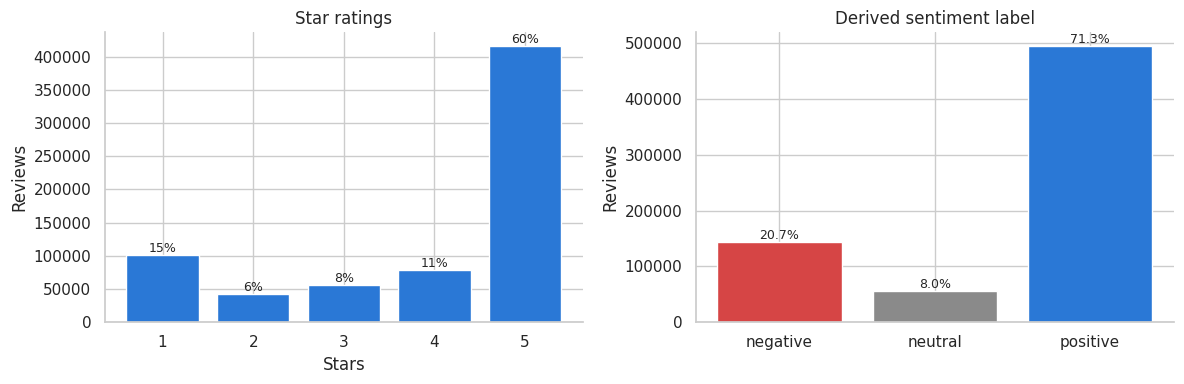

Class imbalance -> accuracy is misleading; we use macro-F1 and balanced accuracy.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rc = df["rating"].value_counts().sort_index()
axes[0].bar(rc.index.astype(int).astype(str), rc.values, color="#2a78d6")
axes[0].set(title="Star ratings", xlabel="Stars", ylabel="Reviews")
for x, v in zip(rc.index.astype(int).astype(str), rc.values):
    axes[0].text(x, v, f"{v/len(df):.0%}", ha="center", va="bottom", fontsize=9)

sc = df["sentiment"].value_counts().reindex(SENT_ORDER)
axes[1].bar(sc.index, sc.values, color=[SENT_COLORS[s] for s in sc.index])
axes[1].set(title="Derived sentiment label", ylabel="Reviews")
for x, v in zip(sc.index, sc.values):
    axes[1].text(x, v, f"{v/len(df):.1%}", ha="center", va="bottom", fontsize=9)
savefig("eda_rating_sentiment")
print("Class imbalance -> accuracy is misleading; we use macro-F1 and balanced accuracy.")

### 4.2 Reviews and sentiment over time

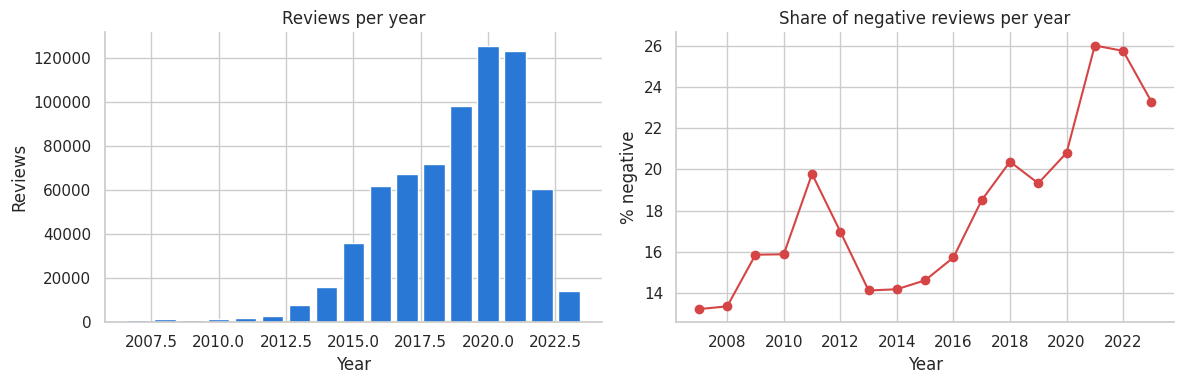

,reviews,avg_rating,pct_negative
year,,,
2016,62042,4.11,15.72
2017,67351,4.02,18.51
2018,71966,3.97,20.38
2019,98148,4.04,19.33
2020,125427,3.97,20.81
2021,123279,3.77,26.02
2022,60654,3.77,25.76
2023,14148,3.87,23.30


In [11]:
yearly = df.groupby("year").agg(reviews=("rating", "size"), avg_rating=("rating", "mean"),
                                pct_negative=("sentiment", lambda s: (s == "negative").mean() * 100))
yearly = yearly[yearly["reviews"] >= 500]          # skip early years with too few reviews to be stable

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(yearly.index, yearly["reviews"], color="#2a78d6")
axes[0].set(title="Reviews per year", xlabel="Year", ylabel="Reviews")
axes[1].plot(yearly.index, yearly["pct_negative"], marker="o", color=SENT_COLORS["negative"])
axes[1].set(title="Share of negative reviews per year", xlabel="Year", ylabel="% negative")
savefig("eda_time_trends")
yearly.round(2).tail(8)

### 4.3 Brands

Distinct brands: 30,745 | reviews with known brand: 92.7%


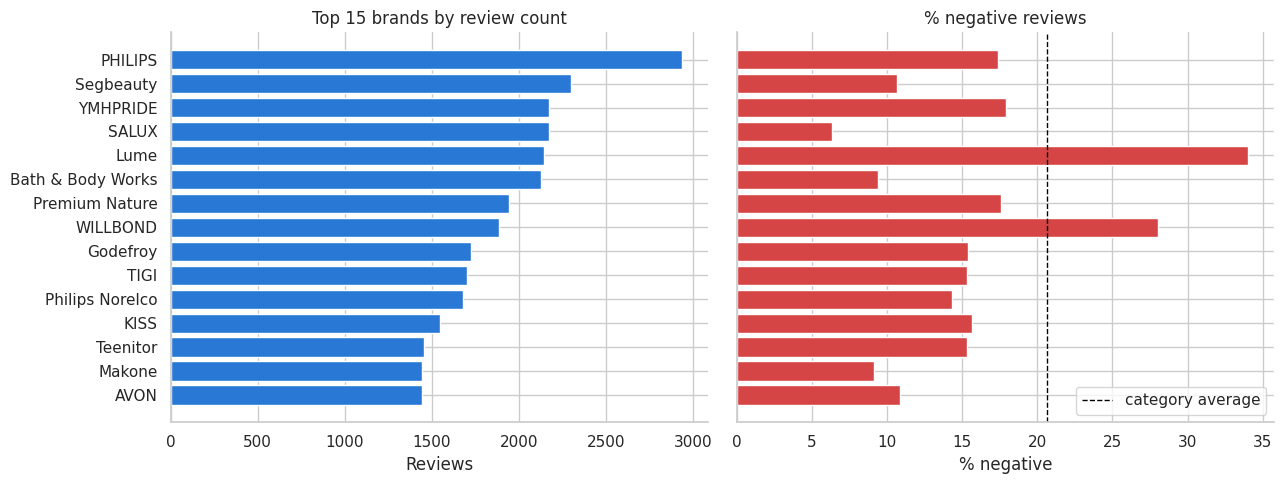

In [12]:
known = df[df["brand"] != "Unknown"]
top_brands = known["brand"].value_counts().head(15).index
brand_stats = (known[known["brand"].isin(top_brands)]
               .groupby("brand").agg(reviews=("rating", "size"), avg_rating=("rating", "mean"),
                                     pct_negative=("sentiment", lambda s: (s == "negative").mean() * 100))
               .sort_values("reviews"))
print(f"Distinct brands: {df['brand'].nunique():,} | reviews with known brand: {len(known)/len(df):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].barh(brand_stats.index, brand_stats["reviews"], color="#2a78d6")
axes[0].set(title="Top 15 brands by review count", xlabel="Reviews")
axes[1].barh(brand_stats.index, brand_stats["pct_negative"], color=SENT_COLORS["negative"])
axes[1].axvline((df["sentiment"] == "negative").mean() * 100, color="black", ls="--", lw=1, label="category average")
axes[1].set(title="% negative reviews", xlabel="% negative"); axes[1].legend(loc="lower right")
savefig("eda_brands")

### 4.4 Review length and helpful votes

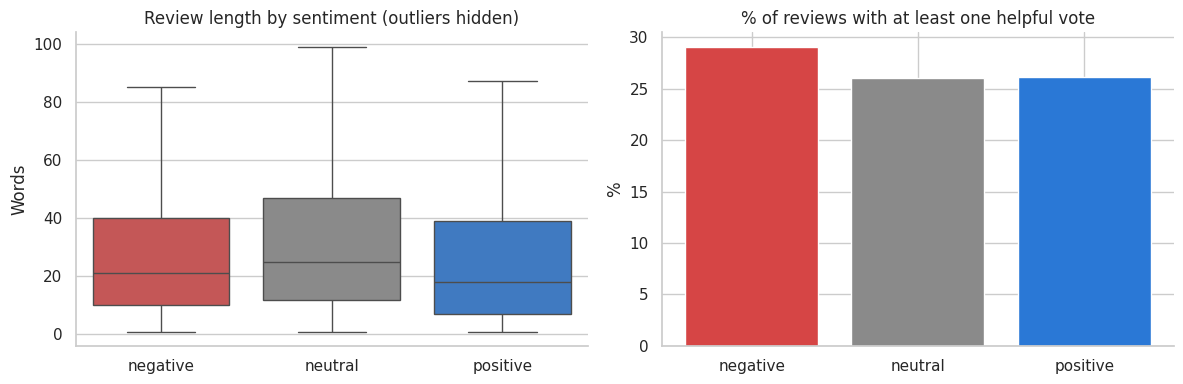

sentiment
negative    21.0
neutral     25.0
positive    18.0
Name: median words, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="sentiment", y="n_words", order=SENT_ORDER, hue="sentiment",
            palette=SENT_COLORS, showfliers=False, legend=False, ax=axes[0])
axes[0].set(title="Review length by sentiment (outliers hidden)", xlabel="", ylabel="Words")

hv = df.groupby("sentiment")["has_votes"].mean().reindex(SENT_ORDER) * 100
axes[1].bar(hv.index, hv.values, color=[SENT_COLORS[s] for s in hv.index])
axes[1].set(title="% of reviews with at least one helpful vote", ylabel="%")
savefig("eda_length_votes")
print(df.groupby("sentiment")["n_words"].median().reindex(SENT_ORDER).rename("median words"))

### 4.5 Which words separate negative from positive reviews?
A first look at what customers praise and complain about, and a preview of the aspects Q1 will mine. The score is a smoothed log-odds ratio: how much more often a word appears in negative reviews than in positive ones. Computed on the sample, for speed.

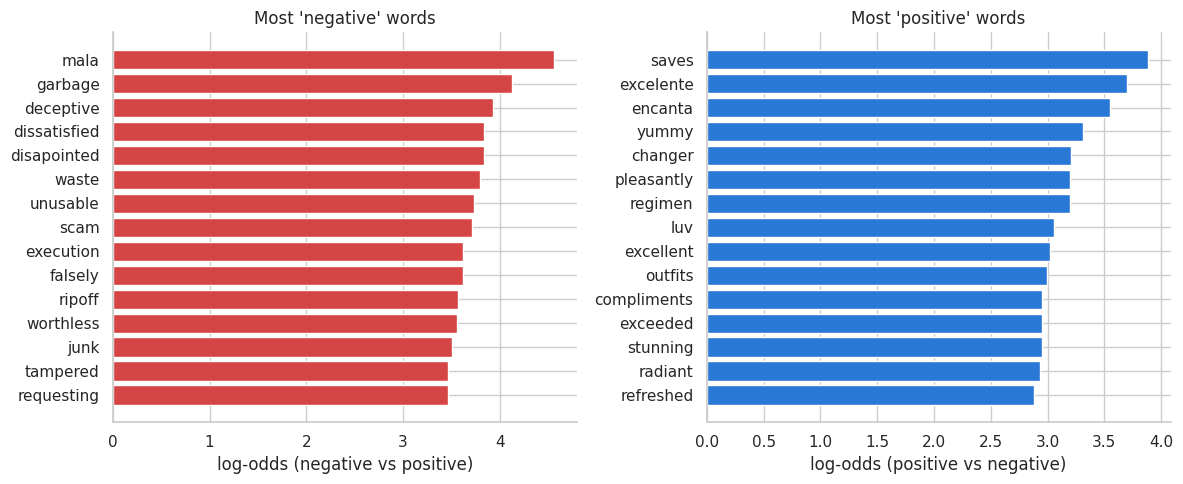

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(stop_words="english", min_df=20, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b", binary=True)
X_words = cv.fit_transform(sample["review_text"].str.lower())
vocab = np.array(cv.get_feature_names_out())
neg = np.asarray(X_words[(sample["sentiment"] == "negative").values].sum(0)).ravel() + 1
pos = np.asarray(X_words[(sample["sentiment"] == "positive").values].sum(0)).ravel() + 1
log_odds = np.log(neg / neg.sum()) - np.log(pos / pos.sum())

top_neg = pd.Series(log_odds, vocab).sort_values(ascending=False).head(15)
top_pos = pd.Series(log_odds, vocab).sort_values().head(15)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(top_neg.index[::-1], top_neg.values[::-1], color=SENT_COLORS["negative"])
axes[0].set(title="Most 'negative' words", xlabel="log-odds (negative vs positive)")
axes[1].barh(top_pos.index[::-1], -top_pos.values[::-1], color=SENT_COLORS["positive"])
axes[1].set(title="Most 'positive' words", xlabel="log-odds (positive vs negative)")
savefig("eda_distinctive_words")

### 4.6 Correlations between numeric features (Spearman: robust to skew and outliers)

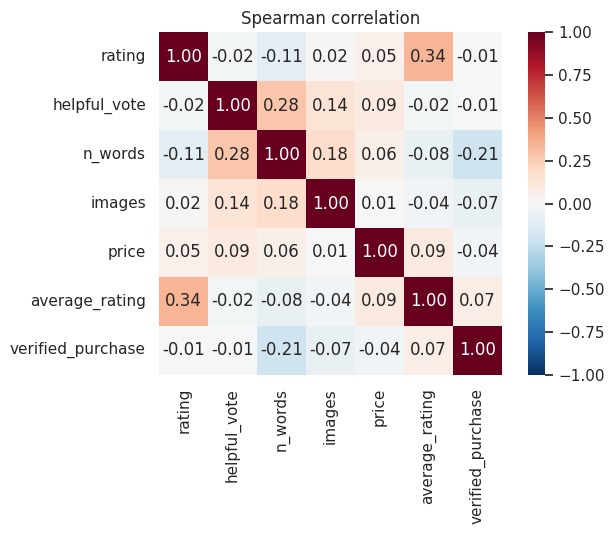

In [15]:
num = df[["rating", "helpful_vote", "n_words", "images", "price", "average_rating"]].copy()
num["verified_purchase"] = df["verified_purchase"].astype(float)
corr = num.corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation")
savefig("eda_correlation")

## 5. Hypothesis tests
With hundreds of thousands of rows almost any difference is "significant", so each test also reports an **effect size** that says whether the difference is big enough to matter. Tests run on the 150K sample.

In [16]:
results_tests = []

# H1: Negative reviews are longer than positive reviews (customers explain problems in detail)
neg_len = sample.loc[sample["sentiment"] == "negative", "n_words"]
pos_len = sample.loc[sample["sentiment"] == "positive", "n_words"]
u, p1 = stats.mannwhitneyu(neg_len, pos_len, alternative="greater")
rank_biserial = 2 * u / (len(neg_len) * len(pos_len)) - 1
results_tests.append(("H1: negative reviews are longer than positive", "Mann-Whitney U (one-sided)",
                      p1, f"rank-biserial r = {rank_biserial:.3f}",
                      f"median words: negative {neg_len.median():.0f} vs positive {pos_len.median():.0f}"))

# H2: Sentiment is independent of verified purchase
ct2 = pd.crosstab(sample["verified_purchase"], sample["sentiment"])
chi2_2, p2, dof2, _ = stats.chi2_contingency(ct2)
v2 = np.sqrt(chi2_2 / (ct2.values.sum() * (min(ct2.shape) - 1)))
neg_rate = sample.groupby("verified_purchase")["sentiment"].apply(lambda s: (s == "negative").mean())
results_tests.append(("H2: sentiment differs for verified vs unverified buyers", "Chi-square independence",
                      p2, f"Cramer's V = {v2:.3f}",
                      f"% negative: verified {neg_rate.get(True, np.nan):.1%} vs unverified {neg_rate.get(False, np.nan):.1%}"))

# H3: Getting a helpful vote depends on sentiment
ct3 = pd.crosstab(sample["sentiment"], sample["has_votes"])
chi2_3, p3, dof3, _ = stats.chi2_contingency(ct3)
v3 = np.sqrt(chi2_3 / (ct3.values.sum() * (min(ct3.shape) - 1)))
vote_rate = sample.groupby("sentiment")["has_votes"].mean().reindex(SENT_ORDER)
results_tests.append(("H3: helpful-vote rate differs by sentiment", "Chi-square independence",
                      p3, f"Cramer's V = {v3:.3f}",
                      ", ".join(f"{k} {v:.1%}" for k, v in vote_rate.items())))

tests_df = pd.DataFrame(results_tests, columns=["hypothesis", "test", "p_value", "effect size", "what we see"])
tests_df["reject H0 (alpha=0.05)"] = tests_df["p_value"] < 0.05
tests_df.to_csv(f"{OUT_DIR}/hypothesis_tests.csv", index=False)
pd.set_option("display.max_colwidth", 80)
tests_df

,hypothesis,test,p_value,effect size,what we see,reject H0 (alpha=0.05)
0,H1: negative reviews are longer than positive,Mann-Whitney U (one-sided),1.101751e-94,rank-biserial r = 0.077,median words: negative 21 vs positive 18,True
1,H2: sentiment differs for verified vs unverified buyers,Chi-square independence,1.073045e-44,Cramer's V = 0.037,% negative: verified 21.1% vs unverified 16.2%,True
2,H3: helpful-vote rate differs by sentiment,Chi-square independence,1.143545e-28,Cramer's V = 0.029,"negative 29.5%, neutral 25.8%, positive 26.4%",True


*Reading effect sizes:* |r| or V below about 0.1 is a small effect, about 0.3 medium, and 0.5 or more large.

## 6. Leakage check for Q3 (helpfulness)
`helpful_vote` is counted **at collection time (2023)**, not when the review was posted. Older reviews have had years to collect votes, so a model can look good just by learning "old = helpful". That is information you would **not** have when a review is posted.

**Consequences for Q3:**
1. Use a **time-based split** (train on older reviews, test on newer ones), not a random split.
2. Do not use the review date or review age as a feature.
3. Report time-split scores as the main result, against a majority baseline on the *same* split.

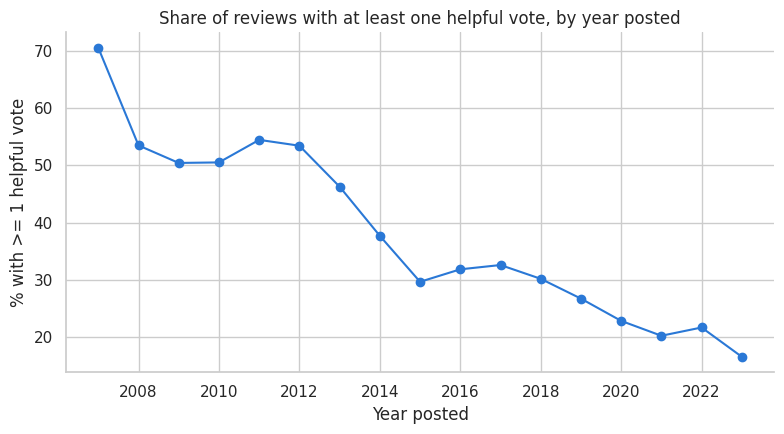

Spearman correlation between year and vote rate: rho = -0.95 (p = 4.79e-09)


In [17]:
age_votes = df.groupby("year").agg(reviews=("has_votes", "size"), pct_with_vote=("has_votes", "mean"))
age_votes = age_votes[age_votes["reviews"] >= 500]
age_votes["pct_with_vote"] *= 100
plt.plot(age_votes.index, age_votes["pct_with_vote"], marker="o", color="#2a78d6")
plt.title("Share of reviews with at least one helpful vote, by year posted")
plt.xlabel("Year posted"); plt.ylabel("% with >= 1 helpful vote")
savefig("leakage_votes_by_year")
rho, p_age = stats.spearmanr(age_votes.index, age_votes["pct_with_vote"])
print(f"Spearman correlation between year and vote rate: rho = {rho:.2f} (p = {p_age:.3g})")

### Label-quality check set (200 reviews to hand-label)
Star-derived labels are noisy (for example, a 5-star review that complains about shipping). This exports 200 reviews, about 67 per class, from the sample. Each team member labels part of them in the `human_label` column, and the next notebook measures how well the stars agree with the human labels.

In [18]:
check_set = (sample.groupby("sentiment", group_keys=False)
             .sample(n=min(67, sample["sentiment"].value_counts().min()), random_state=SEED)
             [["rating", "sentiment", "title", "text"]]
             .rename(columns={"sentiment": "star_label"}))
check_set["human_label"] = ""        # fill with negative / neutral / positive
check_set = check_set.sample(frac=1, random_state=SEED).head(200).reset_index(drop=True)   # shuffle so the labeller can't see the class order
check_set.to_csv(f"{OUT_DIR}/hand_label_check_200.csv", index=False)
print(f"Saved {len(check_set)} reviews to {OUT_DIR}/hand_label_check_200.csv")

Saved 200 reviews to outputs/hand_label_check_200.csv


## 7. Q1 first model: sentiment classifier
**Task:** predict the sentiment (negative / neutral / positive) from the review text (title + body).

**Models compared (all inside a scikit-learn `Pipeline`, so TF-IDF is fitted on the training folds only):**
| Model | Why it's here |
|---|---|
| Majority class (Dummy) | The baseline every model must beat. It always says "positive" |
| TF-IDF + Multinomial NB | A classic, fast text baseline |
| TF-IDF + Complement NB | A Naive Bayes variant designed for imbalanced classes |
| TF-IDF + Logistic Regression (balanced) | A strong linear model; `class_weight="balanced"` gives the rare classes more weight |

**Features:** TF-IDF on word unigrams and bigrams (bigrams catch "not good" and "broke out"), words appearing in at least 5 reviews, at most 100K features, and `sublinear_tf` so long reviews don't dominate.

**Evaluation:** **5-fold stratified cross-validation**, reporting **macro-F1** (each class counts equally, so the rare negative and neutral classes matter) and balanced accuracy. Plain accuracy is shown only for reference.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

N_MODEL = min(100_000, len(sample))     # keeps 5-fold CV of 4 models within ~10 min on a Colab CPU
model_data = sample.sample(n=N_MODEL, random_state=SEED).reset_index(drop=True)
X = model_data["review_text"]
y = model_data["sentiment"]
print(f"Modelling on {len(model_data):,} reviews from the shared sample")
print((y.value_counts(normalize=True).reindex(SENT_ORDER) * 100).round(1).rename("class %"))

def tfidf():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=5, max_features=100_000,
                           sublinear_tf=True, strip_accents="unicode")

models = {
    "Majority baseline": Pipeline([("tfidf", tfidf()), ("clf", DummyClassifier(strategy="most_frequent"))]),
    "TF-IDF + MultinomialNB": Pipeline([("tfidf", tfidf()), ("clf", MultinomialNB(alpha=0.1))]),
    "TF-IDF + ComplementNB": Pipeline([("tfidf", tfidf()), ("clf", ComplementNB(alpha=0.3))]),
    "TF-IDF + LogisticRegression": Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(
        class_weight="balanced", C=4.0, max_iter=2000, random_state=SEED))]),
}

Modelling on 100,000 reviews from the shared sample
sentiment
negative    20.6
neutral      8.1
positive    71.4
Name: class %, dtype: float64


In [20]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"macro_f1": "f1_macro", "balanced_acc": "balanced_accuracy", "accuracy": "accuracy"}

rows = []
for name, pipe in models.items():
    t0 = time.time()
    s = cross_validate(pipe, X, y, cv=cv5, scoring=scoring, n_jobs=1)
    rows.append({"model": name,
                 "macro_F1": s["test_macro_f1"].mean(), "macro_F1_std": s["test_macro_f1"].std(),
                 "balanced_acc": s["test_balanced_acc"].mean(), "accuracy": s["test_accuracy"].mean(),
                 "seconds": time.time() - t0})
    print(f"{name:30s} macro-F1 {rows[-1]['macro_F1']:.3f} ± {rows[-1]['macro_F1_std']:.3f}  ({rows[-1]['seconds']:.0f}s)")

cv_results = pd.DataFrame(rows).sort_values("macro_F1", ascending=False).reset_index(drop=True)
cv_results.to_csv(f"{OUT_DIR}/q1_sentiment_cv_results.csv", index=False)
cv_results.round(3)

Majority baseline              macro-F1 0.278 ± 0.000  (43s)
TF-IDF + MultinomialNB         macro-F1 0.651 ± 0.004  (43s)
TF-IDF + ComplementNB          macro-F1 0.652 ± 0.006  (47s)
TF-IDF + LogisticRegression    macro-F1 0.708 ± 0.003  (197s)


,model,macro_F1,macro_F1_std,balanced_acc,accuracy,seconds
0,TF-IDF + LogisticRegression,0.708,0.003,0.727,0.856,196.692
1,TF-IDF + ComplementNB,0.652,0.006,0.669,0.860,46.940
2,TF-IDF + MultinomialNB,0.651,0.004,0.637,0.870,43.420
3,Majority baseline,0.278,0.000,0.333,0.714,42.929


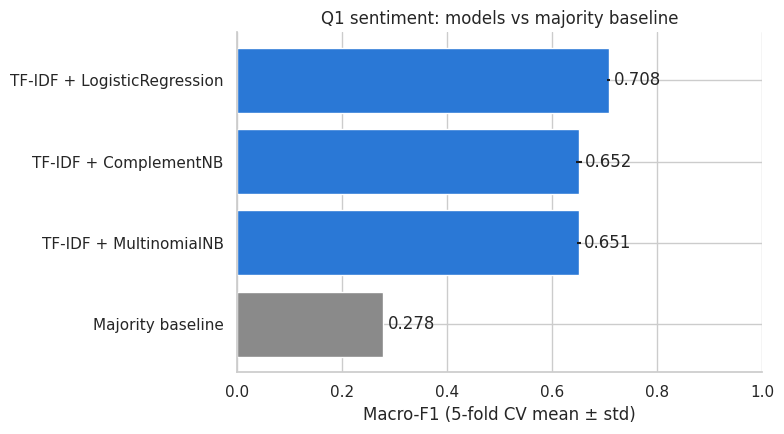

Best model: TF-IDF + LogisticRegression


In [21]:
plot_df = cv_results.sort_values("macro_F1")
colors = ["#8a8a8a" if "baseline" in m else "#2a78d6" for m in plot_df["model"]]
plt.barh(plot_df["model"], plot_df["macro_F1"], xerr=plot_df["macro_F1_std"], color=colors)
for i, v in enumerate(plot_df["macro_F1"]):
    plt.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.xlim(0, 1); plt.xlabel("Macro-F1 (5-fold CV mean ± std)")
plt.title("Q1 sentiment: models vs majority baseline")
savefig("q1_model_comparison")
best_name = cv_results.loc[~cv_results["model"].str.contains("baseline"), "model"].iloc[0]
print("Best model:", best_name)

## 8. Evaluate and interpret the best model
CV gives the score. To *look inside* the model, we refit it on an 80/20 stratified split and examine the held-out 20%.

TF-IDF + LogisticRegression: held-out macro-F1 = 0.703

              precision    recall  f1-score   support

    negative      0.788     0.801     0.795      4113
     neutral      0.331     0.445     0.380      1614
    positive      0.958     0.915     0.936     14273

    accuracy                          0.854     20000
   macro avg      0.692     0.721     0.703     20000
weighted avg      0.872     0.854     0.862     20000



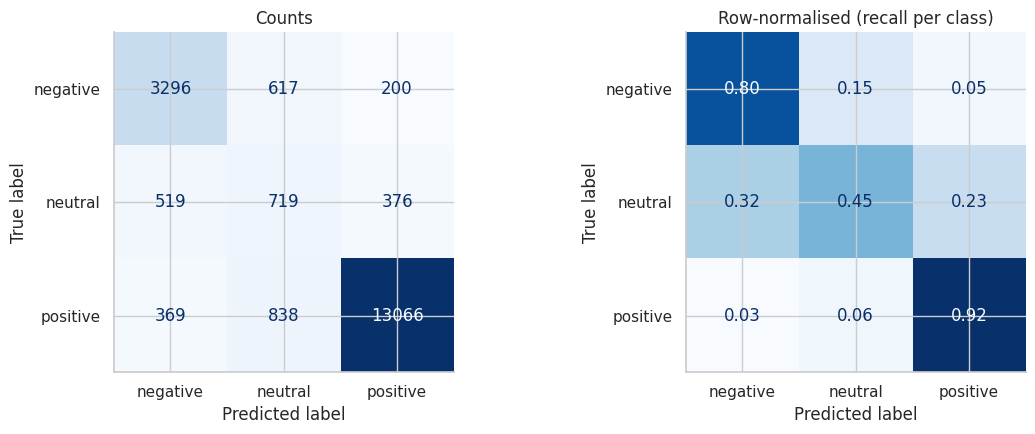

In [22]:
from sklearn.base import clone
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
best = clone(models[best_name]).fit(X_tr, y_tr)
y_pred = best.predict(X_te)

print(f"{best_name}: held-out macro-F1 = {f1_score(y_te, y_pred, average='macro'):.3f}\n")
print(classification_report(y_te, y_pred, labels=SENT_ORDER, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, labels=SENT_ORDER, cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, labels=SENT_ORDER, normalize="true",
                                        cmap="Blues", ax=axes[1], colorbar=False, values_format=".2f")
axes[1].set_title("Row-normalised (recall per class)")
savefig("q1_confusion_matrix")

### What words does the model rely on?
For Logistic Regression each class has a weight per word. The highest weights are the words that push a review towards that class, so this is a first, rough view of what customers praise and complain about. Part of this is "fake", "rash" and "smell" style aspect language, which Q1's aspect mining (next milestone) will extract properly with FP-Growth.

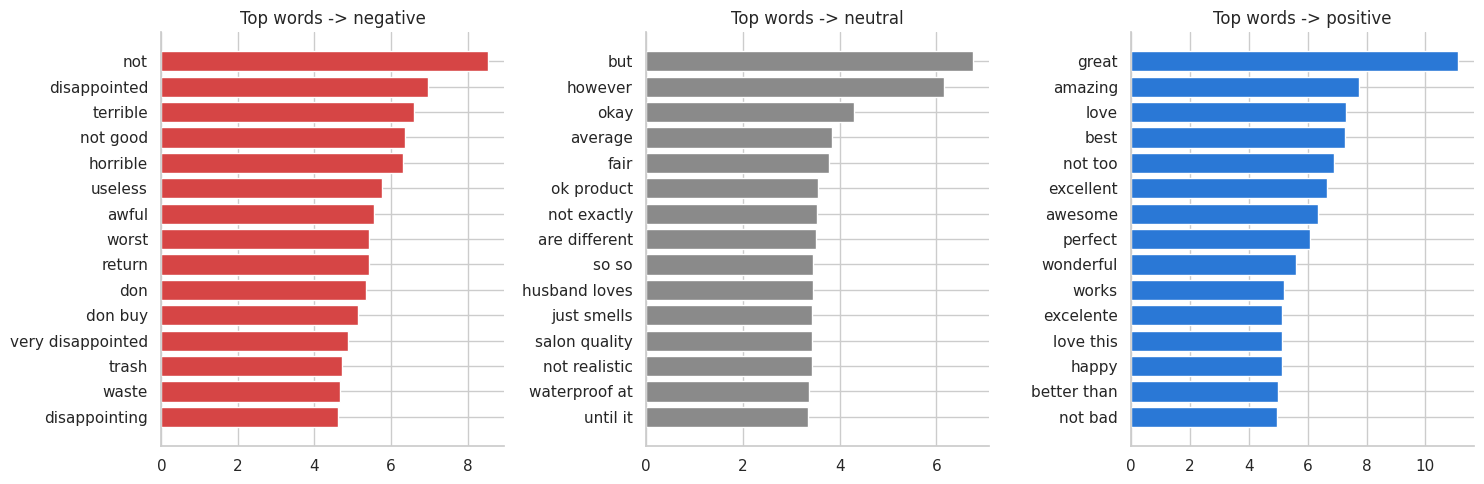

In [23]:
clf = best.named_steps["clf"]
feat = np.array(best.named_steps["tfidf"].get_feature_names_out())
if hasattr(clf, "coef_"):
    weights = clf.coef_
elif hasattr(clf, "feature_log_prob_"):
    weights = clf.feature_log_prob_ - clf.feature_log_prob_.mean(0)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, cls in zip(axes, SENT_ORDER):
    k = list(clf.classes_).index(cls)
    top = np.argsort(weights[k])[-15:]
    ax.barh(feat[top], weights[k][top], color=SENT_COLORS[cls])
    ax.set_title(f"Top words -> {cls}")
savefig("q1_top_words")

### Error analysis: where does the model go wrong?

In [24]:
err = pd.DataFrame({"text": X_te.values, "true": y_te.values, "pred": y_pred})
err = err.join(model_data.loc[X_te.index, ["rating"]].reset_index(drop=True))
err["confidence"] = best.predict_proba(X_te).max(1)

print("Most common mistakes (true -> predicted):")
print(err[err["true"] != err["pred"]].groupby(["true", "pred"]).size().sort_values(ascending=False).to_string())

def show(true, pred, n=4):
    ex = err[(err["true"] == true) & (err["pred"] == pred)].sort_values("confidence", ascending=False).head(n)
    print(f"\n=== true {true} -> predicted {pred} (most confident mistakes) ===")
    for _, r in ex.iterrows():
        print(f"[{r.rating:.0f} stars | conf {r.confidence:.2f}] {r.text[:220]}")

show("positive", "negative")
show("negative", "positive")
show("neutral", "positive")

Most common mistakes (true -> predicted):
true      pred    
positive  neutral     838
negative  neutral     617
neutral   negative    519
          positive    376
positive  negative    369
negative  positive    200

=== true positive -> predicted negative (most confident mistakes) ===
[5 stars | conf 1.00] Mine died. Mine died. I charged it. It lit up but didn’t work at all. I am very disappointed! I also wasted my money.
[5 stars | conf 0.99] Not as described. This item tangles my hair. Bristles are too hard and always seem to be too hot and burns, very disappointed, was hoping for a better product, end up buying a different one which works 100 percent better
[5 stars | conf 0.99] Did not work at all, when buttom pushed. Nothing came on. Not worth the money, bought for my girlfriend, she charged it and when she cut it nothing, was broken. Never used.
[5 stars | conf 0.99] Nothing. Nothing

=== true negative -> predicted positive (most confident mistakes) ===
[2 stars | conf 1.00] . 

**What to look for (fill in after you run it):** most mistakes involve the **neutral** class. 3-star reviews mix praise and complaints ("works OK but smells weird"), so they sit between the other two classes. Confident "positive → negative" mistakes are often **label noise**: the stars say positive but the text complains, which is exactly what the 200-review hand-label check will measure. Sarcasm and comparisons ("better than my old one, which was terrible") also trip up a bag-of-words model.

### Try it: paste a review (this becomes the 'paste a review' feature of the Streamlit app)

In [25]:
def predict_review(text):
    proba = best.predict_proba([clean_text(text)])[0]
    probs = dict(zip(best.classes_, proba))
    label = max(probs, key=probs.get)
    return label, {k: round(float(probs[k]), 3) for k in SENT_ORDER}

for t in ["This serum smells amazing and my skin feels so soft. Will buy again!",
          "Broke me out in a rash after two days. Pretty sure it's a fake, packaging looked different.",
          "It's okay. Does the job but the scent is a bit strong and it's overpriced."]:
    print(predict_review(t), "<-", t)

('positive', {'negative': 0.0, 'neutral': 0.001, 'positive': 0.999}) <- This serum smells amazing and my skin feels so soft. Will buy again!
('negative', {'negative': 0.865, 'neutral': 0.117, 'positive': 0.019}) <- Broke me out in a rash after two days. Pretty sure it's a fake, packaging looked different.
('neutral', {'negative': 0.001, 'neutral': 0.995, 'positive': 0.005}) <- It's okay. Does the job but the scent is a bit strong and it's overpriced.


In [26]:
import joblib
final_model = clone(models[best_name]).fit(X, y)          # refit on all modelling data for the app
joblib.dump(final_model, f"{OUT_DIR}/q1_sentiment_model.joblib")
print("Saved", f"{OUT_DIR}/q1_sentiment_model.joblib",
      f"({os.path.getsize(f'{OUT_DIR}/q1_sentiment_model.joblib')/1e6:.1f} MB)")

Saved outputs/q1_sentiment_model.joblib (5.5 MB)


## 9. Summary for this milestone

In [27]:
base = cv_results.loc[cv_results["model"] == "Majority baseline", "macro_F1"].iloc[0]
top = cv_results.iloc[0]
print("REVIEW OPINION MINER: MILESTONE SUMMARY")
print("=" * 60)
print(f"Data           : {len(df_raw):,} raw reviews joined with {len(meta):,} products ({match_rate:.1%} matched)")
print(f"Cleaning       : {n0 - len(df):,} rows removed -> {len(df):,} clean reviews")
print(f"Sample         : {N_SAMPLE:,} random reviews (seed {SEED}), representative (chi-square p = {p:.2f})")
print(f"EDA            : ratings, time trends, brands, length, votes, distinctive words, correlations")
print(f"Hypothesis     : {tests_df['reject H0 (alpha=0.05)'].sum()} of {len(tests_df)} null hypotheses rejected (see effect sizes)")
print(f"Leakage (Q3)   : vote rate vs year rho = {rho:.2f} -> Q3 must use a time-based split")
print(f"Q1 best model  : {top['model']}  macro-F1 {top['macro_F1']:.3f} ± {top['macro_F1_std']:.3f}  "
      f"(baseline {base:.3f})")
print("\nFiles in outputs/:", sorted(os.listdir(OUT_DIR)))
print("Charts in figures/:", sorted(os.listdir(FIG_DIR)))

REVIEW OPINION MINER: MILESTONE SUMMARY
Data           : 701,528 raw reviews joined with 112,590 products (100.0% matched)
Cleaning       : 7,981 rows removed -> 693,547 clean reviews
Sample         : 150,000 random reviews (seed 42), representative (chi-square p = 0.47)
EDA            : ratings, time trends, brands, length, votes, distinctive words, correlations
Hypothesis     : 3 of 3 null hypotheses rejected (see effect sizes)
Leakage (Q3)   : vote rate vs year rho = -0.95 -> Q3 must use a time-based split
Q1 best model  : TF-IDF + LogisticRegression  macro-F1 0.708 ± 0.003  (baseline 0.278)

Files in outputs/: ['data_dictionary.csv', 'hand_label_check_200.csv', 'hypothesis_tests.csv', 'q1_sentiment_cv_results.csv', 'q1_sentiment_model.joblib', 'sample_150k.parquet']
Charts in figures/: ['eda_brands.png', 'eda_correlation.png', 'eda_distinctive_words.png', 'eda_length_votes.png', 'eda_rating_sentiment.png', 'eda_time_trends.png', 'leakage_votes_by_year.png', 'q1_confusion_matrix.png

### Next steps
- **Q1 (Ali):** tune C / alpha and the n-gram range; measure label quality on the 200 hand-labelled reviews; **aspect mining** (spaCy noun phrases → FP-Growth, Apriori vs FP-Growth, the effect of `min_support`); aspect sentiment per brand.
- **Q2 (Ayesha):** TruncatedSVD + K-means on the negative reviews of the shared sample; choose k with silhouette and elbow; name the clusters.
- **Q3 (Awais):** rerun on the shared sample with the **time-based split** and a baseline on the same split (see Part 6).
- **App:** load `q1_sentiment_model.joblib` for the "paste a review" page.

*Dataset citation:* Hou, Y., Li, J., He, Z., Yan, A., Chen, X., & McAuley, J. (2024). *Bridging Language and Items for Retrieval and Recommendation.* arXiv:2403.03952.